# Angles between functions: how much does a new monomial add?

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 4, Section "Inner Product Spaces" (the angle between two functions, Example "Monomials Are Nearly Parallel").

An inner product turns a space of functions into a geometric space: the Cauchy–Schwarz inequality lets us define
the angle $\theta$ between two non-zero functions,
$$\cos\theta = \frac{\langle u, v\rangle}{\|u\|\,\|v\|}.$$
When we approximate the solution of a variational problem by a combination of a few chosen functions, each new
function should bring a *new direction*. This notebook measures how new those directions really are, for the
most natural choice, the monomials $1, x, x^2, \dots$.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell (number of functions, family, inner product) and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

# ---------------------------------------------------------------- PARAMETERS
N       = 8            # number of basis functions
family  = "monomials"  # "monomials": 1, x, ..., x^(N-1)
                       # "bubbles":   x(1-x), x^2(1-x), ...  (vanish at both ends, as in a clamped bar)
                       # "sines":     sin(pi x), sin(2 pi x), ...
product = "L2"         # "L2":     <u,v> = int u v dx
                       # "H1":     <u,v> = int (u v + u' v') dx
                       # "energy": <u,v> = int u' v' dx   (an inner product only for functions vanishing at an end)
# ---------------------------------------------------------------------------

## 1. The basis functions and the inner product

All integrals on $(0,1)$ are computed with Gauss–Legendre quadrature on 200 points: exact for polynomials up to
degree 399, and accurate to machine precision for the sines. Each family returns the values of the functions and
of their derivatives at the quadrature points.

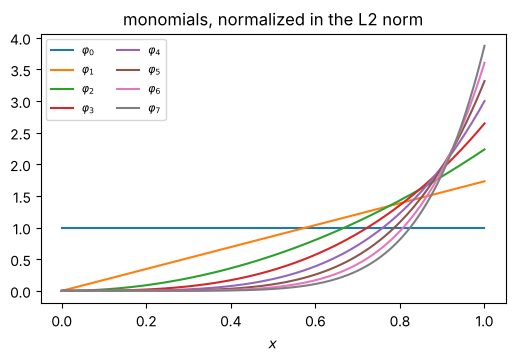

In [2]:
xg, wg = np.polynomial.legendre.leggauss(200)
xq, wq = (xg + 1) / 2, wg / 2                      # quadrature on (0,1)

def basis(family, N, x):
    """Values and derivatives of the N basis functions at the points x (arrays of shape N x len(x))."""
    n = np.arange(N)[:, None]
    if family == "monomials":
        phi  = x**n
        dphi = n * x**np.maximum(n - 1, 0)
    elif family == "bubbles":                       # x^(n+1) (1-x)
        phi  = x**(n + 1) * (1 - x)
        dphi = (n + 1) * x**n * (1 - x) - x**(n + 1)
    elif family == "sines":
        phi  = np.sin((n + 1) * np.pi * x)
        dphi = (n + 1) * np.pi * np.cos((n + 1) * np.pi * x)
    else:
        raise ValueError(family)
    return phi, dphi

def gram_matrix(phi, dphi, product):
    """G_ij = <phi_i, phi_j> computed by quadrature."""
    if product == "L2":
        return (phi * wq) @ phi.T
    if product == "H1":
        return (phi * wq) @ phi.T + (dphi * wq) @ dphi.T
    if product == "energy":
        return (dphi * wq) @ dphi.T
    raise ValueError(product)

phi, dphi = basis(family, N, xq)
G = gram_matrix(phi, dphi, product)

x = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
for k, f in enumerate(basis(family, N, x)[0]):
    ax.plot(x, f / np.sqrt(G[k, k]), label=f"$\\varphi_{{{k}}}$")
ax.set_title(f"{family}, normalized in the {product} norm")
ax.set_xlabel("$x$"); ax.legend(ncol=2, fontsize=8)
plt.show()

For monomials and the $L^2$ product the Gram matrix has a closed form,
$\langle x^i, x^j\rangle = \int_0^1 x^{i+j}\,dx = 1/(i+j+1)$: it is the **Hilbert matrix**.

In [3]:
np.set_printoptions(precision=4, suppress=True, linewidth=110)
print(G[:5, :5])

[[1.     0.5    0.3333 0.25   0.2   ]
 [0.5    0.3333 0.25   0.2    0.1667]
 [0.3333 0.25   0.2    0.1667 0.1429]
 [0.25   0.2    0.1667 0.1429 0.125 ]
 [0.2    0.1667 0.1429 0.125  0.1111]]


## 2. Angles between pairs of functions

The matrix $\cos\theta_{ij} = G_{ij}/\sqrt{G_{ii}G_{jj}}$. Values close to 1 mean nearly parallel functions.

angle between the last two functions: 4.096 degrees


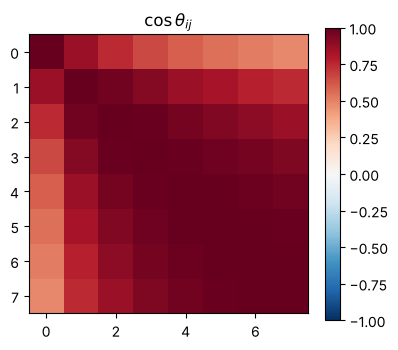

In [4]:
d = np.sqrt(np.diag(G))
C = G / np.outer(d, d)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_title(r"$\cos\theta_{ij}$"); fig.colorbar(im)
plt.show()
print("angle between the last two functions: %.3f degrees" % np.degrees(np.arccos(C[-1, -2])))

## 3. How much is new? The angle with the span of the previous functions

Pairwise angles do not tell the whole story: a new function can be far from each of its predecessors and still be
almost a combination of them. The relevant angle $\theta_n$ is the one between $\varphi_n$ and the subspace spanned
by $\varphi_0,\dots,\varphi_{n-1}$:
$$\sin\theta_n = \frac{\text{distance of } \varphi_n \text{ from that subspace}}{\|\varphi_n\|}.$$
The distance is exactly what the Gram–Schmidt procedure computes at step $n$, before normalizing. In matrix form,
Gram–Schmidt is the Cholesky factorization $G = LL^{\mathsf T}$, and the distance is the diagonal entry $L_{nn}$.

For the monomials in $L^2(0,1)$ there is a closed form, $\sin\theta_n = 1/\binom{2n}{n}$
(the part of $x^n$ orthogonal to the lower powers is the Legendre polynomial of degree $n$, divided by its
leading coefficient).

In [5]:
try:
    L = np.linalg.cholesky(G)
    sin_theta = np.diag(L) / np.sqrt(np.diag(G))
except np.linalg.LinAlgError:
    sin_theta = None
    print("Cholesky failed: in double precision the last functions are indistinguishable from")
    print("combinations of the previous ones. Reduce N.")

if sin_theta is not None:
    print(" n   theta_n [deg]" + ("   exact (monomials, L2)" if (family, product) == ("monomials", "L2") else ""))
    for n, s in enumerate(sin_theta):
        line = f"{n:2d}   {np.degrees(np.arcsin(min(s, 1))):12.6f}"
        if (family, product) == ("monomials", "L2") and n > 0:
            line += f"   {np.degrees(np.arcsin(1 / comb(2 * n, n))):12.6f}"
        print(line)

 n   theta_n [deg]   exact (monomials, L2)
 0      90.000000
 1      30.000000      30.000000
 2       9.594068       9.594068
 3       2.865984       2.865984
 4       0.818539       0.818539
 5       0.227365       0.227365
 6       0.062008       0.062008
 7       0.016695       0.016695


Each new monomial adds less than the previous one: roughly, $\theta_n$ is divided by 4 at every step.
The first entry, $90^\circ$, is a convention: $\varphi_0$ has no predecessors.

## Things to try
1. Increase `N`: from which $N$ does the Cholesky factorization fail? The new monomials are then, in double
   precision, combinations of the previous ones.
2. Set `family = "sines"`: the functions $\sin(n\pi x)$ are orthogonal in $L^2$, and every $\theta_n$ is $90^\circ$.
   Are they still orthogonal for `product = "H1"`? And for `product = "energy"`?
3. Set `family = "bubbles"` and `product = "energy"`: the polynomials $x^{n+1}(1-x)$ vanish at both ends, as the
   displacement of a bar clamped at both ends. Do they bring more novelty than the monomials?